In [233]:
%%capture
%pip install pandas numpy matplotlib seaborn python-calamine scikit-learn

In [234]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk

In [235]:
X = pd.read_excel('dataset-uci.xlsx', engine='calamine')

In [236]:
print("Missing values:", X.isnull().sum().sum())
print("\nColumn names:\n", X.columns.tolist())

Missing values: 0

Column names:
 ['Gallstone Status', 'Age', 'Gender', 'Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Extracellular Water (ECW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vitamin D']


In [ ]:
# Results
#X = X.drop(205)
#X = X.drop(318)

y = X["Gallstone Status"]
X_reduced = X.drop(columns=['Gallstone Status'])

# Same as Body Mass Index (BMI)
X_reduced = X_reduced.drop(columns=['Height', 'Weight', 'Obesity (%)'])

# Same as Total Body Water (TBW)
X_reduced = X_reduced.drop(columns=['Extracellular Water (ECW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)'])

# Same as Total Body Fat Ratio (TBFR) (%)
X_reduced = X_reduced.drop(columns=['Total Fat Content (TFC)', 'Lean Mass (LM) (%)'])

# Same as Visceral Fat Area (VFA)
X_reduced = X_reduced.drop(columns=['Visceral Fat Rating (VFR)'])

print(f"Features reduced from {X.shape[1]} to {X_reduced.shape[1]}")

Features reduced from 39 to 29


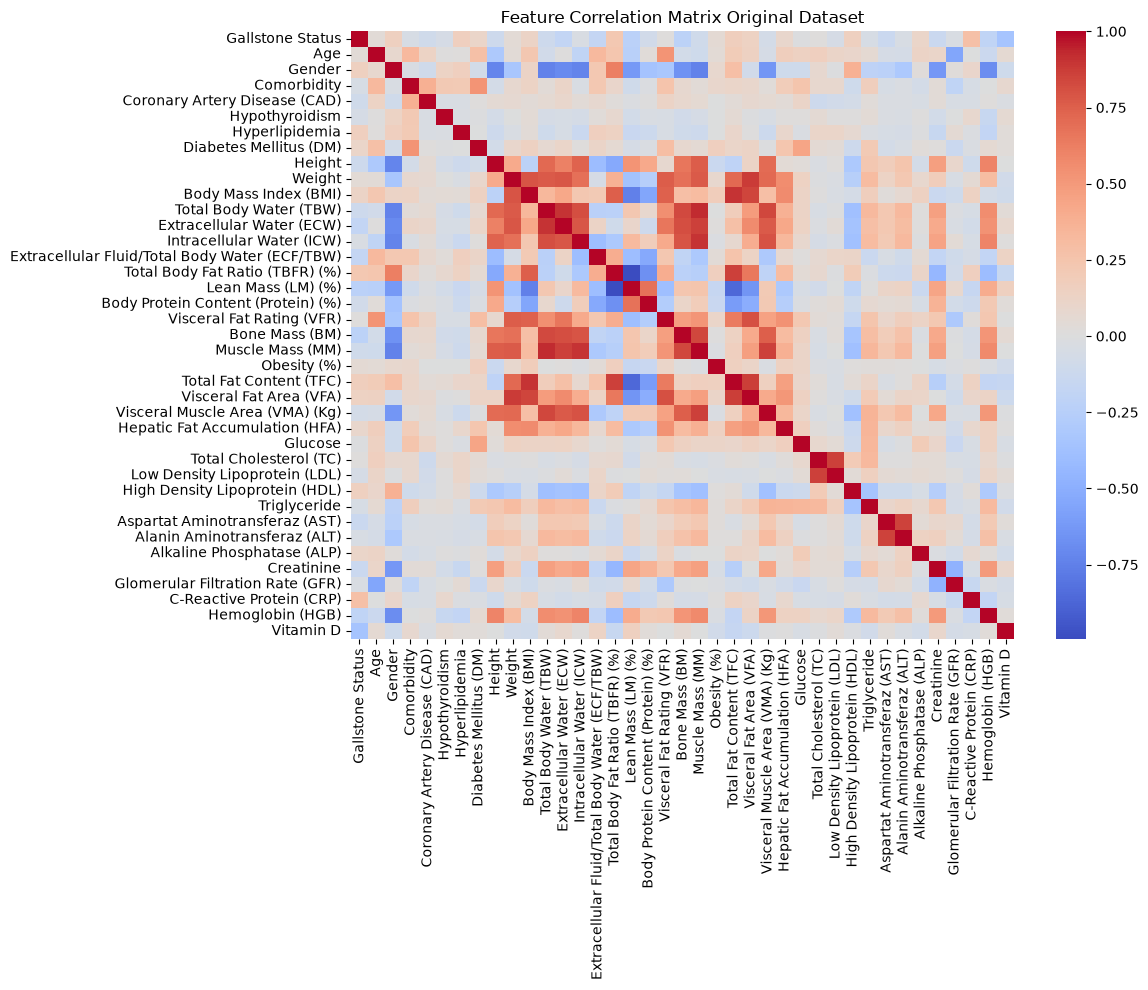

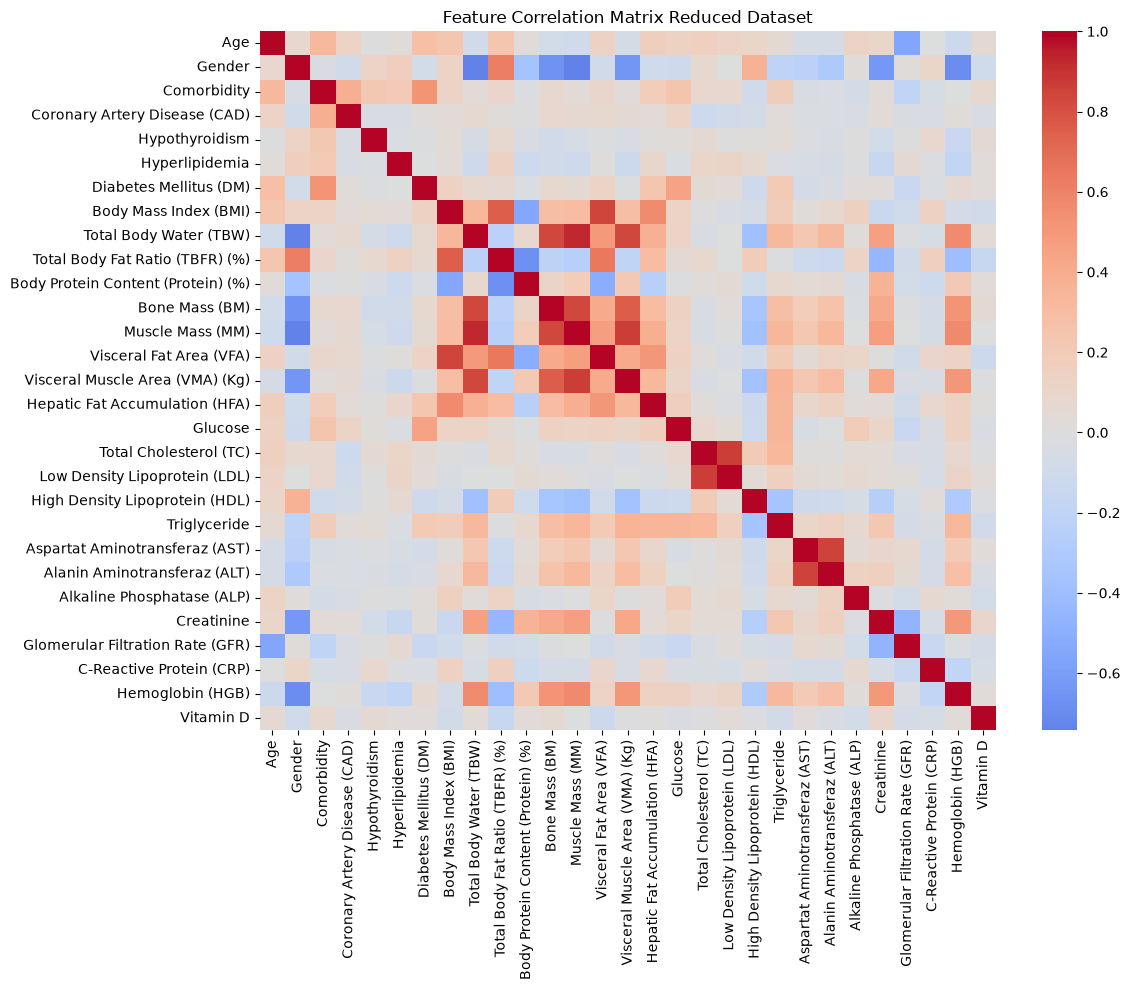

In [238]:
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix Original Dataset")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(X_reduced.corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix Reduced Dataset")
plt.tight_layout()
plt.show()

In [239]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X_reduced, y, test_size=0.3)
print ('Train set:', X_train.shape,  y_train.shape)
print ('Test set:', X_test.shape,  y_test.shape)

Train set: (223, 29) (223,)
Test set: (96, 29) (96,)


In [240]:
from sklearn.tree import DecisionTreeClassifier
drugTree = DecisionTreeClassifier(criterion="entropy", max_depth = 3)
drugTree.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [241]:
predTree = drugTree.predict(X_test)
# Define the data for the two columns
data = {
    'Predited Values': predTree,
    'Actual Values': y_test
}

# Create the DataFrame
df = pd.DataFrame(data)

# Display the DataFrame
#print(df)

Decision Trees's Accuracy:  0.6875


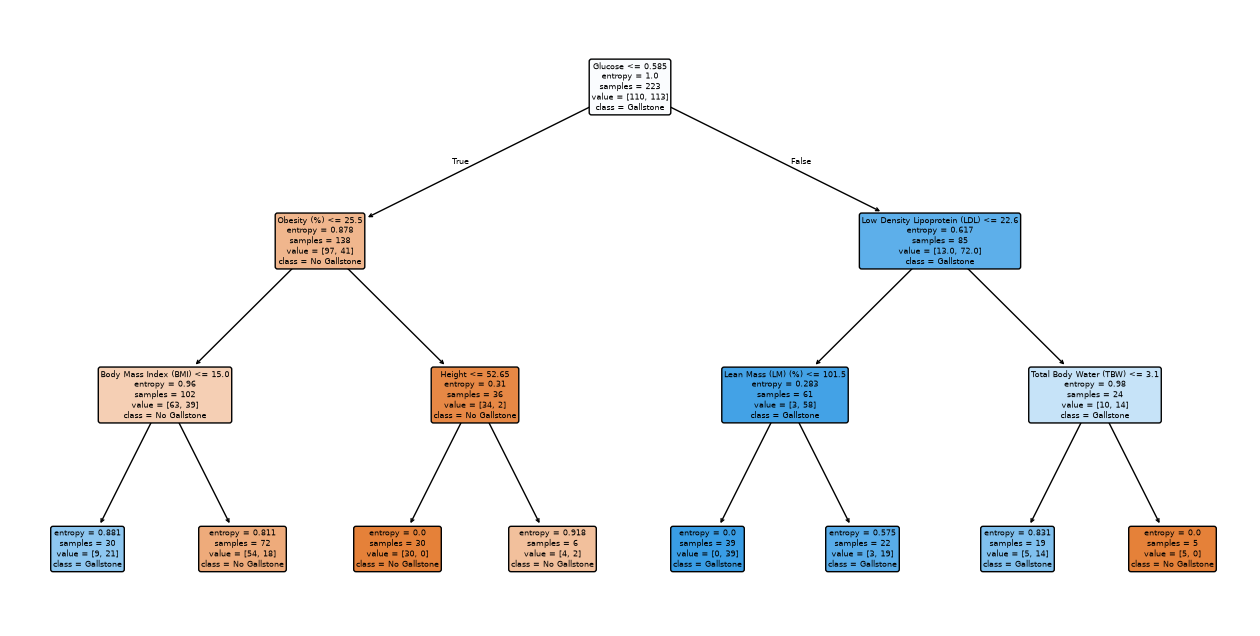

In [242]:
from sklearn import metrics
from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt

print("Decision Trees's Accuracy: ", metrics.accuracy_score(y_test, predTree))

plt.figure(figsize=(16, 8))
plot_tree(drugTree, feature_names=list(X.columns), class_names=['No Gallstone', 'Gallstone'], filled=True, rounded=True)
plt.show()